# Tesing the Partition of Unity 

In [1]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np

from skimage import data
from skimage.transform import resize

from pou import gen_weight_grid

torch.Size([3, 3, 32, 32])


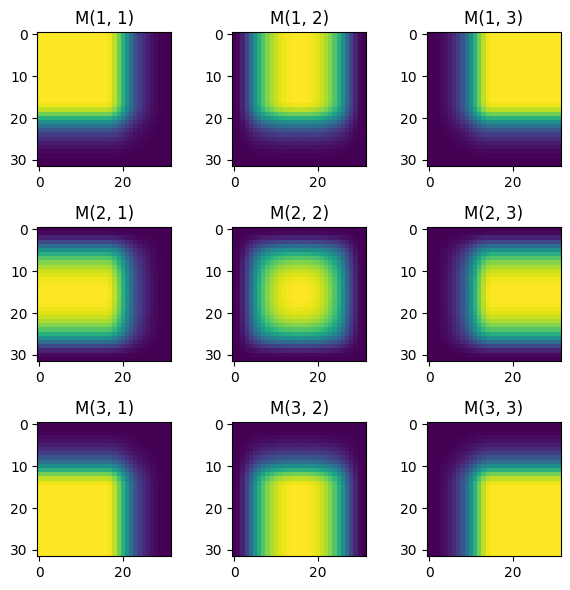

In [2]:
block_res = 32
expand_ratio = 2
weight_grid = gen_weight_grid(block_res, expand_ratio)
print(weight_grid.shape)

# plot grid 
x = weight_grid.cpu().numpy()  # convert to numpy if needed
grid_size = weight_grid.shape[0]
fig, axes = plt.subplots(grid_size, grid_size, figsize=(6, 6))
# fig.tight_layout(pad=1.0)
for i in range(grid_size):
    for j in range(grid_size):
        axes[i, j].imshow(x[i, j], cmap='viridis')
        axes[i, j].set_title(f'M({i+1}, {j+1})')
        # axes[i, j].axis('off')
plt.tight_layout()
plt.savefig('weight_grid.png', dpi=150)
plt.show()

torch.Size([1, 1, 64, 64])
tensor(0.)


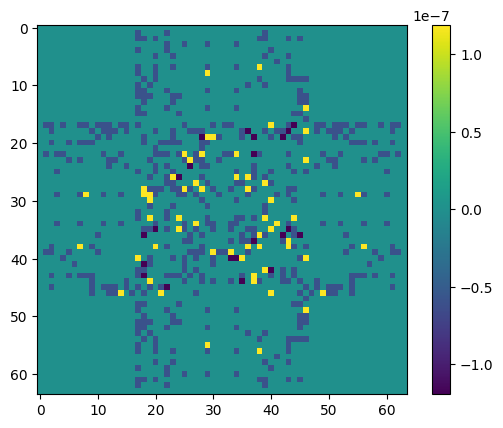

In [3]:

patch_size = 32
stride = 16

output_size=(64, 64)
grid_h, grid_w = weight_grid.shape[:2]
num_patches = grid_h * grid_w

W_patches = weight_grid.view(num_patches, patch_size * patch_size).T.unsqueeze(0)  # shape (1, 1024, 49)

# Step 2: Add back using F.fold
weight_sum = F.fold(W_patches, output_size=output_size, kernel_size=patch_size, stride=stride)
print(weight_sum.shape)
print(weight_sum.sum() - 64*64)

# weight sum to one 
plt.imshow(weight_sum[0][0] - 1)
plt.colorbar()
plt.show()


(64, 64, 3)
torch.Size([3, 64, 64])


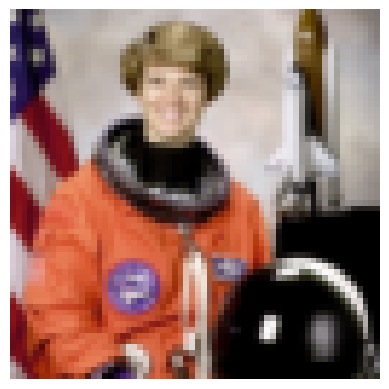

In [4]:

# Load a real photo (astronaut)
img = data.astronaut()  # shape: (512,512,3), uint8

# Resize to 64x64
img64 = resize(img, (64,64), anti_aliasing=True)
print(img64.shape)  # (64, 64, 3)
# Convert to torch tensor and permute to C,H,W
tensor_img = torch.from_numpy(img64).permute(2,0,1).float()

print(tensor_img.shape)  # (3, 64, 64)

plt.imshow(img64)
plt.axis('off')
plt.show()


torch.Size([1, 3072, 9])
torch.Size([1, 3, 3, 3, 32, 32])
torch.Size([1, 3, 3, 3, 32, 32])


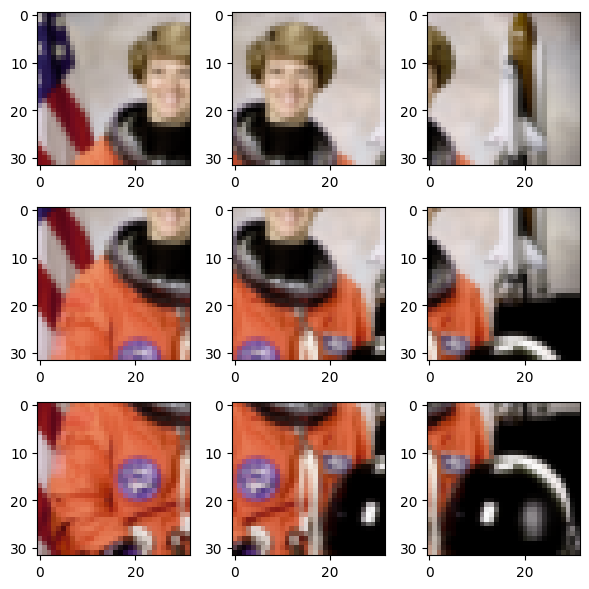

In [5]:
images = tensor_img.unsqueeze(0)
B, C, H, W = images.shape
weights = weight_grid

# Step 1: Extract patches
patches = F.unfold(images, kernel_size=patch_size, stride=stride)  # (B, C*patch_size*patch_size, num_patches)
print(patches.shape)

# Step 2: Get grid dimensions (e.g., 7x7 from 49 patches)
num_patches = patches.shape[-1]
grid_h = grid_w = int(num_patches ** 0.5)
assert grid_h * grid_w == num_patches, "Image dimensions not compatible with patching"


# Step 3: Reshape patches to (B, C, grid_h, grid_w, patch_size, patch_size)
patches = patches.transpose(1, 2).reshape(B, grid_h, grid_w, C, patch_size, patch_size)
print(patches.shape)

patches = patches.permute(0, 3, 1, 2, 4, 5)  # (B, C, grid_h, grid_w, patch_size, patch_size)
print(patches.shape)

# plot grid 
x = patches[0].cpu().permute(1,2,3,4,0)  # convert to numpy if needed
grid_size = x.shape[0]
fig, axes = plt.subplots(grid_size, grid_size, figsize=(6, 6))
# fig.tight_layout(pad=1.0)
for i in range(grid_size):
    for j in range(grid_size):
        axes[i, j].imshow(x[i, j], cmap='viridis')
        # axes[i, j].axis('off')
plt.tight_layout()
plt.show()


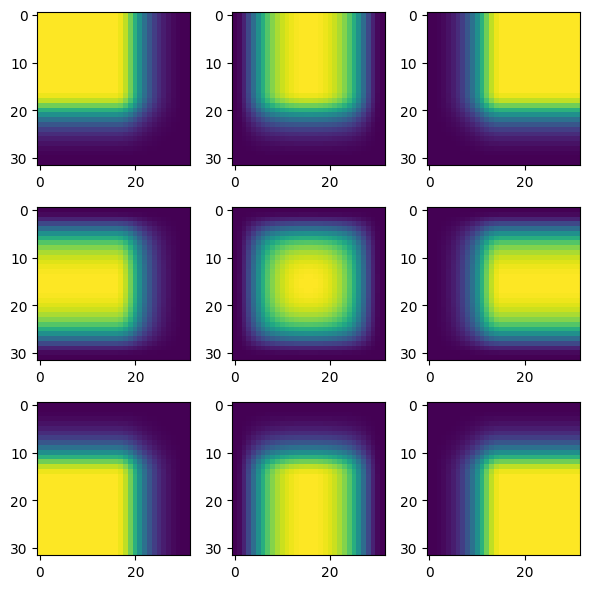

In [6]:

# Step 4: Apply weights (broadcast over batch and channels)
weighted_patches = patches * weights.unsqueeze(0).unsqueeze(0)  # (B, C, grid_h, grid_w, patch_size, patch_size)

# plot grid 
x = weight_grid.cpu().numpy()  # convert to numpy if needed
grid_size = weight_grid.shape[0]
fig, axes = plt.subplots(grid_size, grid_size, figsize=(6, 6))
# fig.tight_layout(pad=1.0)
for i in range(grid_size):
    for j in range(grid_size):
        axes[i, j].imshow(x[i, j], cmap='viridis')
        # axes[i, j].axis('off')
plt.tight_layout()
plt.show()

In [7]:

# Step 5: Reshape to (B, C*patch_size*patch_size, num_patches) for folding
weighted_patches = weighted_patches.permute(0, 2, 3, 1, 4, 5)  # (B, grid_h, grid_w, C, patch_size, patch_size)
weighted_patches_plt = weighted_patches.clone()
weighted_patches = weighted_patches.reshape(B, num_patches, C * patch_size * patch_size).transpose(1, 2)



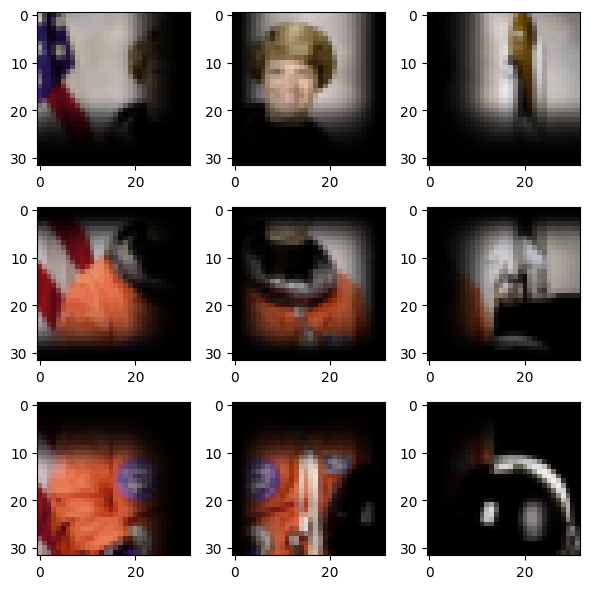

In [8]:

# plot grid 
x = weighted_patches_plt[0].cpu().permute(0,1,3,4,2)  # convert to numpy if needed
grid_size = x.shape[0]
fig, axes = plt.subplots(grid_size, grid_size, figsize=(6, 6))
# fig.tight_layout(pad=1.0)
for i in range(grid_size):
    for j in range(grid_size):
        axes[i, j].imshow(x[i, j], cmap='viridis')
        # axes[i, j].axis('off')
plt.tight_layout()
plt.show()



In [9]:

# Step 6: Fold back into original image shape
reconstructed = F.fold(weighted_patches, output_size=(H, W), kernel_size=patch_size, stride=stride)

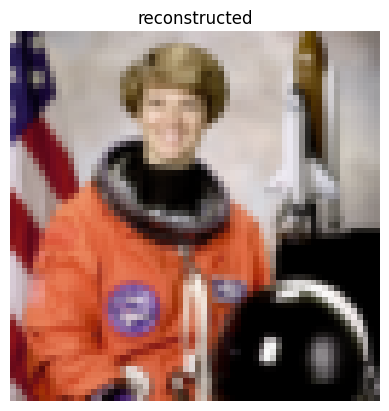

9.314168103458087e-09


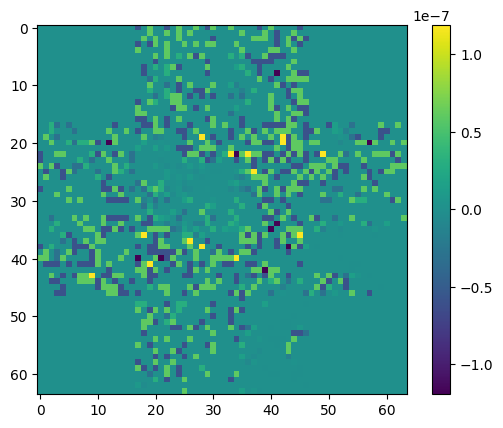

In [10]:
# recon image 
plt.imshow(reconstructed[0].permute(1,2,0).detach().numpy())
plt.axis('off')
plt.title('reconstructed')
plt.show()

# error 
er = images - reconstructed
print(er.abs().mean().item())
plt.imshow(er[0][0])
plt.colorbar()
plt.show()